[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-PY_Ed2026/blob/main/python/P17/P17-1_EDA_CORRIGE.ipynb)

# Analyse exploratoire des données

Chapitre 17 du livre *Python pour l'ingénierie mécanique, industrielle et productique*.

## Cadrage

**Contexte industriel.** Le service qualité vous remet le suivi de production de vingt mille machines : des cases vides, des colonnes que personne n'a regardées, des valeurs étranges. Avant de modéliser, vous voudriez savoir si ces données tiennent debout et ce qu'il faudra corriger ?

**Objectif terminal.** Ce chapitre montre comment, avec pandas, seaborn et scipy, pour l'analyse comme pour les modèles du livre Méca-IA.

**Objectif instrumental.**

- Cadrer un projet, lire un classeur et décrire sa forme et ses cases vides.
- Mettre le test de côté avant tout croisement avec la cible.
- Lire chaque variable, puis ses liens avec la cible, sur l'apprentissage seul.
- Repérer les valeurs aberrantes et juger un écart par un test.
- Consigner dans une fiche les opérations de préparation à prévoir.
- Lire une répartition empirique et la densité conjointe de mesures.

**Critère de résultat.** Chaque exercice atteint son résultat attendu, que des contrôles du notebook vérifient.

**Vérification.** Beaucoup d'exercices donnent une seconde voie : un calcul fait par deux chemins indépendants est un calcul qu'on peut croire.

**Prérequis.** Les chapitres 5, 7, 8 et 15, après une filière scientifique.

## Source de données

| Fichier | Lignes | Colonnes | Unités |
|:-|-:|-:|:-|
| `MecaIA-Suivi_Production_Machines.xlsx` | 20000 | 14 | ancienneté en années, complexité et efficacité sans dimension, nombre de capteurs entier, utilisation en proportion, température en °C, vibrations en mm/s, consommation en kWh/h, productivité en pièces/h, indice de santé de 0 à 100 |
| `MecaIA-Surveillance_Vibratoire.xlsx` | 150 | 25 | vitesse en tr/min, charge en kN, pression en bar, débit en L/min, vibrations en mm/s, température en °C, émission acoustique en dB, courant en A, puissance en kW, durée de vie en h |
| `MecaIA-TimeSeries_RUL.xlsx` | 18855 | 10 | cycles en heures, charge en %, vitesse en tr/min, température en K, pression en bar, vibration en mm/s, courant en A, contamination en ppm |

Les classeurs sont lus dans le dossier `donnees` du dépôt `Meca-PY_Ed2026` ; ouvert seul, par exemple dans Colab, le notebook les télécharge une fois depuis le dépôt public.

## Exercices

| N° | Exercice | Durée indicative |
|:-|:-|-:|
| 17.1 | Cadrer, lire et découper un second jeu | 15 min |
| 17.2 | Comparer les classes de productivité | 15 min |
| 17.3 | Les corrélations de la surveillance vibratoire | 15 min |
| 17.4 | Aberrants et tests sur les vibrations | 20 min |
| 17.5 | La fiche de décisions du suivi de production (défi) | 25 min |

Dans le sujet, les cellules marquées `# Votre code :` sont à écrire ; le corrigé les donne résolues. Chaque exercice se termine par des contrôles qui comparent votre résultat à celui du livre.

### Lecture des jeux

Les jeux se cherchent d'abord dans le dépôt cloné, à deux dossiers au-dessus de ce notebook.

In [1]:
from pathlib import Path
import urllib.request

# Les jeux du chapitre : nom du classeur et adresse de la copie publique.
JEUX = {
    "MecaIA-Suivi_Production_Machines.xlsx": "https://raw.githubusercontent.com/philippe-amuzuga/Meca-PY_Ed2026/main/donnees/MecaIA-Suivi_Production_Machines.xlsx",
    "MecaIA-Surveillance_Vibratoire.xlsx": "https://raw.githubusercontent.com/philippe-amuzuga/Meca-PY_Ed2026/main/donnees/MecaIA-Surveillance_Vibratoire.xlsx",
    "MecaIA-TimeSeries_RUL.xlsx": "https://raw.githubusercontent.com/philippe-amuzuga/Meca-PY_Ed2026/main/donnees/MecaIA-TimeSeries_RUL.xlsx",
}

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-PY_Ed2026", "donnees")]
dossier = next((d for d in candidats if all((d / f).is_file() for f in JEUX)), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique des jeux depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    for fichier, adresse in JEUX.items():
        if not (dossier / fichier).is_file():
            try:
                urllib.request.urlretrieve(adresse, dossier / fichier)
            except OSError as erreur:
                raise FileNotFoundError(
                    "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
DONNEES = dossier
print("jeux lus dans le dossier des données :", ", ".join(JEUX))

jeux lus dans le dossier des données : MecaIA-Suivi_Production_Machines.xlsx, MecaIA-Surveillance_Vibratoire.xlsx, MecaIA-TimeSeries_RUL.xlsx


### En-tête de reproductibilité

Versions des bibliothèques employées : les valeurs du livre sont celles de ces versions, avec des graines fixées.

In [2]:
# En-tête de reproductibilité : versions employées par ce notebook.
import platform
from importlib.metadata import version

print("Python", platform.python_version())
print("matplotlib", version("matplotlib"))
print("numpy", version("numpy"))
print("pandas", version("pandas"))
print("scikit-learn", version("scikit-learn"))
print("scipy", version("scipy"))
print("seaborn", version("seaborn"))

Python 3.12.0
matplotlib 3.11.1
numpy 2.4.6
pandas 3.0.5
scikit-learn 1.9.0
scipy 1.18.0
seaborn 0.13.2


### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas les dossiers du dépôt. La cellule suivante ne télécharge rien : elle cherche `donnees/` et `outils/` (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-PY_Ed2026`), ajoute `outils/` au chemin de recherche de Python, et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez les dossiers `donnees` et `outils` à la racine de l'espace de travail, et téléversez-y les fichiers listés, pris dans le dépôt. Ce notebook lit les jeux de sa première cellule et reproduit le code des modules cités ; les téléverser sert à les importer dans vos propres cellules.

In [3]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
import sys
from pathlib import Path

JEUX_LUS = list(JEUX)                                  # les classeurs de la première cellule
MODULES_DU_LIVRE = ["meca_donnees.py", "meca_style.py"]                          # fichiers de outils/


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-PY_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees, outils = chercher("donnees"), chercher("outils")
if outils is not None and str(outils) not in sys.path:
    sys.path.insert(0, str(outils))
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
manque += [f"outils/{nom}" for nom in MODULES_DU_LIVRE if outils is None or not (outils / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Fonctions du module du livre (`meca_donnees.py`)

Le code ci-dessous reprend, tel qu'il est écrit dans le livre, les fonctions du module employées dans ce notebook ; ce code est fourni tel quel.

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import (GridSearchCV, KFold, ShuffleSplit, StratifiedKFold, cross_val_score,
                                     learning_curve, train_test_split)


ORDRE_OPERATIONS = ["exclure", "imputer", "encoder", "mettre à l'échelle", "transformer", "extraire", "sélectionner"]


ORDRE_EMPLOI = [
    ("EDA-01", "cadrer", "17.1", ()),
    ("EDA-02", "lire_classeur", "17.1", ("EDA-01",)),
    ("EDA-03", "forme_tableau", "17.1", ("EDA-02",)),
    ("EDA-04", "bilan_manquants", "17.1", ("EDA-03",)),
    ("EDA-05", "colonnes_inutiles", "17.1", ("EDA-04",)),
    ("DEC-01", "decouper", "17.1", ("EDA-05",)),
    ("EDA-06", "tracer_distributions", "17.2", ("DEC-01",)),
    ("EDA-07", "resume_numerique", "17.2", ("EDA-06",)),
    ("EDA-09", "correlations", "17.3", ("EDA-07",)),
    ("EDA-10", "relations_paires", "17.3", ("EDA-09",)),
    ("EDA-15", "liens_entre", "17.3", ("EDA-10",)),
    ("EDA-08", "tableau_croise", "17.3", ("EDA-15",)),
    ("EDA-12", "variable_deterministe", "17.3", ("EDA-08",)),
    ("EDA-11", "aberrants_tukey", "17.4", ("EDA-12",)),
    ("EDA-13", "fiche_decisions", "17.5", ("EDA-11",)),
    ("EDA-14", "mesures_datees", "9.1", ("EDA-02",)),
    ("DEC-02", "preprocessing_Xy", "18.1", ("EDA-13", "DEC-01")),
    ("DEC-03", "decouper_stratifie", "18.1", ("DEC-02",)),
    ("DEC-04", "sensibilite_split", "18.1", ("DEC-03",)),
    ("DEC-05", "separateurs_validation", "18.1", ("DEC-04",)),
    ("DEC-06", "evaluation_lc", "18.1", ("DEC-05",)),
    ("E-1", "encoder_cible", "18.2", ("DEC-06",)),
    ("E-2", "encoder_variables", "18.2", ("E-1",)),
    ("E-3", "encoder_manuel", "18.2", ("E-2",)),
    ("N-1", "pourquoi_echelles", "18.2", ("E-3",)),
    ("N-2", "mise_echelle_minmax", "18.2", ("N-1",)),
    ("N-3", "mise_echelle_standard", "18.2", ("N-2",)),
    ("N-4", "choisir_echelle", "18.2", ("N-3", "EDA-11")),
    ("I-1", "imputer_statistique", "18.3", ("N-4",)),
    ("I-2", "imputer_voisins", "18.3", ("I-1",)),
    ("I-3", "indicateur_manquants", "18.3", ("I-2",)),
    ("S-1", "filtrer_variance", "18.4", ("I-3",)),
    ("S-2", "selection_score", "18.4", ("S-1",)),
    ("S-3", "selection_modele", "18.4", ("S-2",)),
    ("S-4", "elimination_recursive", "18.4", ("S-3",)),
    ("S-5", "controle_selection", "18.4", ("S-4",)),
    ("X-5", "preprocessing_grandeurs", "18.4", ("S-5",)),
    ("X-1", "termes_polynomiaux", "18.4", ("X-5",)),
    ("X-2", "transformer_distribution", "18.4", ("X-1",)),
    ("X-3", "decouper_en_classes", "18.4", ("X-2",)),
    ("X-4", "transformer_fonction", "18.4", ("X-3",)),
    ("A-1", "workflow_quatre_temps", "18.5", ("X-4",)),
    ("A-2", "pipeline_simple", "18.5", ("A-1",)),
    ("A-3", "preparer", "18.5", ("A-2",)),
    ("A-4", "decrire_pipeline", "18.5", ("A-3",)),
]


def dossier_jeux():
    """Dossier des classeurs : celui de la cellule de lecture du notebook."""
    return DONNEES


def cadrer(terminal, instrumental, critere, verification):
    """Amont : aucune, départ de la chaîne. Cellule de texte qui cadre le projet avant tout code.
    >>> print(cadrer("Prévoir l'état", "Classer", "exactitude", "sur le test")[:21])
    **Objectif terminal**
    """
    etapes = [("Objectif terminal", terminal), ("Objectif instrumental", instrumental),
              ("Critère de résultat", critere), ("Vérification", verification)]
    return "\n".join(f"**{nom}** : {valeur}" for nom, valeur in etapes)


def lire_classeur(source, dossier=None, **options):
    """Amont : EDA-01. Lit un classeur Excel et garde l'original : renvoie (data, df), df est une copie de travail.
    >>> import io; tampon = io.BytesIO(); JOUET.to_excel(tampon, index=False)
    >>> data, df = lire_classeur(tampon); df.shape, df is not data
    ((6, 5), True)
    """
    if isinstance(source, str):
        source = Path(dossier or dossier_jeux()) / source
    data = pd.read_excel(source, **options)
    return data, data.copy()


def forme_tableau(df):
    """Amont : EDA-02. Forme du tableau : lignes, colonnes, types (numériques, booléens, textes).
    >>> f = forme_tableau(JOUET); list(f.values())
    [6, 5, 3, 0, 2]
    """
    forme = {"lignes": df.shape[0], "colonnes": df.shape[1], "numeriques": df.select_dtypes("number").shape[1],
             "booleens": df.select_dtypes("bool").shape[1]}
    forme["textes"] = df.shape[1] - forme["numeriques"] - forme["booleens"]
    return forme


def bilan_manquants(df, ax=None):
    """Amont : EDA-03. Taux de manquants par colonne, cellules et lignes touchées ; carte des manquants si ax est donné.
    >>> t = bilan_manquants(JOUET); t["cellules"], t["lignes"], round(float(t["taux"].iloc[0]), 3)
    (2, 2, 0.167)
    """
    taux = (df.isna().sum() / df.shape[0]).sort_values(ascending=False)
    if ax is not None:
        sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=ax)
    return {"taux": taux, "cellules": int(df.isna().sum().sum()), "lignes": int(df.isna().any(axis=1).sum())}


def colonnes_inutiles(df, seuil_vide=0.9, seuil_dominante=0.999):
    """Amont : EDA-04. Colonnes à retirer : presque vides, constantes ou presque, identifiants (une valeur par ligne).
    >>> colonnes_inutiles(JOUET)
    {'vides': [], 'constantes': ['longueur_mm'], 'identifiants': []}
    """
    vides = [c for c in df if df[c].isna().mean() > seuil_vide]
    dominante = df.apply(lambda s: s.value_counts(normalize=True).max() if s.notna().any() else 1.0)
    constantes = [c for c in df if c not in vides and dominante[c] >= seuil_dominante]
    identifiants = [c for c in df if c not in vides + constantes and df[c].nunique() == len(df)
                    and not pd.api.types.is_float_dtype(df[c])]
    return {"vides": vides, "constantes": constantes, "identifiants": identifiants}


def decouper(df, test_size=0.2, random_state=42, afficher=False):
    """Amont : EDA-05. Met le test de côté avant tout croisement avec la cible ; contrôle les tailles.
    >>> apprentissage, test = decouper(JOUET, test_size=0.5); len(apprentissage), len(test)
    (3, 3)
    """
    df_train, df_test = train_test_split(df, test_size=test_size, random_state=random_state)
    assert len(df_train) + len(df_test) == len(df) and not set(df_train.index) & set(df_test.index)
    if afficher:
        print(f"{'Train set size ':.<25} {df_train.shape}\n{'Test set size ':.<25} {df_test.shape}")
    return df_train, df_test


def tracer_distributions(df, colonnes=None, par_ligne=4):
    """Amont : DEC-01. Une distribution par variable numérique (histplot de seaborn) ; renvoie la figure.
    >>> fig = tracer_distributions(JOUET); len(fig.axes)
    3
    """
    cols = list(df.select_dtypes("number").columns if colonnes is None else colonnes)
    lignes = -(-len(cols) // par_ligne)
    fig, axes = plt.subplots(lignes, min(par_ligne, len(cols)), figsize=(2.3 * par_ligne, 1.9 * lignes), squeeze=False)
    for ax, col in zip(axes.flat, cols):
        sns.histplot(df[col], ax=ax, color="0.45", edgecolor="white")
        ax.set_xlabel(f"asymétrie {df[col].skew():.1f}".replace(".", ","))
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    return fig


def resume_numerique(df, groupe=None):
    """Amont : EDA-06. Statistiques d'ensemble, ou moyennes et effectifs par groupe (à lire sur l'apprentissage).
    >>> resume_numerique(JOUET)["count"].tolist(), resume_numerique(JOUET, "etat")["effectif"].tolist()
    ([5.0, 6.0, 6.0], [3, 3])
    """
    if groupe is None:
        return df.describe().T
    moyennes = df.groupby(groupe).mean(numeric_only=True)
    return moyennes.assign(effectif=df[groupe].value_counts().reindex(moyennes.index))


def correlations(df, cible=None, ax=None):
    """Amont : EDA-07. Matrice de corrélation, ou corrélations avec la cible triées ; carte annotée si ax est donné.
    >>> correlations(JOUET).shape, correlations(JOUET, "charge_kN").index.tolist()
    ((3, 3), ['epaisseur_mm', 'longueur_mm'])
    """
    corr = df.corr(numeric_only=True)
    if ax is not None:
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="Greys", vmin=-1, vmax=1, ax=ax)
    return corr if cible is None else corr[cible].drop(cible).sort_values()


def relations_paires(df, colonnes, hue=None, n_max=400):
    """Amont : EDA-09. Nuages deux à deux (pairplot) sur un échantillon, la classe en teinte ; renvoie la grille.
    >>> grille = relations_paires(JOUET, ["epaisseur_mm", "charge_kN"], hue="etat"); len(grille.axes.flat)
    4
    """
    echantillon = df.sample(min(n_max, len(df)), random_state=0)
    garde = list(colonnes) + ([hue] if hue else [])
    return sns.pairplot(echantillon[garde], hue=hue, diag_kind="hist", plot_kws={"s": 8}, height=1.6)


def liens_entre(df_num, seuil=0.85):
    """Amont : EDA-10. Paires liées à plus de seuil par Pearson et par Spearman (redondantes), et paires monotones courbes.
    >>> a = pd.DataFrame({"u": [1.0, 2.0, 3.0, 4.0], "v": [2.0, 4.0, 6.0, 8.0], "w": [4.0, 1.0, 3.0, 2.0]})
    >>> redondantes, courbes = liens_entre(a); redondantes[["a", "b"]].values.tolist(), len(courbes)
    ([['u', 'v']], 0)
    """
    liens = df_num.corr().stack().to_frame("r")
    liens["rho"] = df_num.corr(method="spearman").stack()
    liens = liens.reset_index(names=["a", "b"]).query("a < b")
    cond = liens[["r", "rho"]].abs().min(axis=1) >= seuil
    return liens[cond], liens[liens.rho.abs() - liens.r.abs() > 0.2]


def tableau_croise(ligne, colonne, ax=None):
    """Amont : EDA-15. Effectifs avec totaux et parts par ligne ; carte annotée des parts si ax est donné.
    >>> eff, parts = tableau_croise(JOUET["materiau"], JOUET["etat"]); int(eff.loc["Total", "Total"]), parts.shape
    (5, (2, 2))
    """
    effectifs = pd.crosstab(ligne, colonne, margins=True, margins_name="Total")
    parts = pd.crosstab(ligne, colonne, normalize="index").round(3)
    if ax is not None:
        sns.heatmap(parts, annot=True, fmt=".2f", cbar=False, cmap="Greys", vmin=0, vmax=1, ax=ax)
    return effectifs, parts


def variable_deterministe(df, col, cible):
    """Amont : EDA-08. Part des lignes dont la cible se déduit de la variable seule (1,0 : variable à exclure).
    >>> variable_deterministe(JOUET.assign(x=[1, 1, 1, 9, 9, 9]), "x", "etat")
    1.0
    """
    d = df[[col, cible]].dropna()
    if pd.api.types.is_numeric_dtype(d[col]):
        g = d.groupby(cible)[col].agg(["min", "median", "max"]).sort_values("median")
        coupures = np.sort(((g["max"] + g["min"].shift(-1)) / 2).dropna().to_numpy())
        predite = g.index.to_numpy()[np.searchsorted(coupures, d[col].to_numpy())]
        return float((predite == d[cible].to_numpy()).mean())
    return float(d.groupby(col)[cible].agg(lambda v: v.value_counts().iloc[0]).sum() / len(d))


def aberrants_tukey(serie, k=1.5):
    """Amont : EDA-12. Bornes de Tukey (quartiles ± k fois l'écart interquartile) et masque des valeurs hors bornes.
    >>> bas, haut, hors = aberrants_tukey(JOUET["epaisseur_mm"]); (bas, haut, int(hors.sum()))
    (1.75, 3.75, 1)
    """
    q1, q3 = serie.quantile([0.25, 0.75])
    ecart = q3 - q1
    bas, haut = q1 - k * ecart, q3 + k * ecart
    return bas, haut, (serie < bas) | (serie > haut)


def fiche_decisions(df, cible, exclure=()):
    """Amont : EDA-11. Fiche de décisions : variable, constat, opération prévue, rangées dans l'ordre d'emploi.
    >>> fiche_decisions(JOUET, "etat", exclure=["longueur_mm"]).iloc[:, 2].tolist()
    ['exclure', 'imputer', 'imputer', 'encoder', "mettre à l'échelle", 'transformer']
    """
    cols = [c for c in df.columns if c not in (cible, *exclure)]
    num = [c for c in cols if pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c])]
    regles = ([(c, "inutile ou déterminée", "exclure") for c in exclure]
              + [(c, f"{100 * df[c].isna().mean():.1f} % manquants", "imputer") for c in cols if df[c].isna().any()]
              + [(c, f"{df[c].nunique()} modalités", "encoder") for c in cols if c not in num]
              + [(c, f"asymétrie {df[c].skew():.1f}", "transformer" if abs(df[c].skew()) > 1 else "mettre à l'échelle")
                 for c in num])
    fiche = pd.DataFrame(regles, columns=["variable", "constat", "operation"])
    return fiche.sort_values("operation", key=lambda o: o.map(ORDRE_OPERATIONS.index), kind="stable", ignore_index=True)


def mesures_datees(df, col_heures, debut="2026-01-01", fenetre=24):
    """Amont : EDA-02. Mesures datées : index temporel depuis un compteur d'heures, moyennes par jour, lissage centré.
    >>> t = pd.DataFrame({"h": range(48), "x": range(48)}); d, jour, lisse = mesures_datees(t, "h")
    >>> d.index[1].hour, jour["x"]["mean"].tolist(), float(lisse["x"].iloc[24])
    (1, [11.5, 35.5], 23.5)
    """
    d = df.set_index(pd.Timestamp(debut) + pd.to_timedelta(df[col_heures], unit="h")).drop(columns=col_heures)
    d.index.name = "horodatage"
    jour = d.resample("D").agg(["mean", "std", "min", "max"])
    lisse = d.rolling(window=fenetre, center=True).mean()
    return d, jour, lisse

### Préparation

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
sns.set_theme(style="ticks", palette=["0.15", "0.45", "0.7", "0.85"])
CIBLE = "etat_sante_machine"

## Exercice 17.1 : Cadrer, lire et découper un second jeu (15 min)

Le classeur `MecaIA-Surveillance_Vibratoire.xlsx` suit des machines tournantes : chaque ligne porte des relevés et la durée de vie restante en heures, `duree_vie_restante_RUL_h`. Cadrez le projet en quatre phrases, lisez le classeur avec `lire_classeur`, décrivez sa forme, repérez les colonnes presque constantes, puis découpez avec la graine $42$ et les réglages par défaut.

**Résultat attendu.** 150 lignes et 25 colonnes, 120 lignes d'apprentissage ; deux colonnes de texte constantes, `ALIMENTATION` et `TYPE_LUBRIFIANT`.

**Seconde voie.** La somme des deux parts redonne le nombre de lignes lu ; aucun index n'est commun aux deux parts.

**Indication.** Appelez `cadrer` avec une durée de vie à prévoir, une régression, un coefficient de détermination et un test ouvert une fois. `lire_classeur` rend `data` et `df`. `forme_tableau` et `colonnes_inutiles(df)` donnent la forme et les constantes. `decouper(df)` prend vingt pour cent des lignes pour le test.

In [6]:
# Solution :
print(cadrer("prévoir l'état de santé de chaque machine", "classer les machines en quatre états",
             "exactitude sur le test", "le test n'est ouvert qu'une fois, à la fin"))
data, df = lire_classeur("MecaIA-Suivi_Production_Machines.xlsx")
forme = forme_tableau(df)
print("dimensions :", df.shape, " numériques :", forme["numeriques"], " textes :", forme["textes"])
fig, ax = plt.subplots(figsize=(3.4, 2.4))
manquants = bilan_manquants(df, ax=ax)
print("manquants : %d cellules, %d lignes touchées" % (manquants["cellules"], manquants["lignes"]))
colonnes_vides = (manquants["taux"] > 0).sum()
taux_max = manquants["taux"].iloc[0]
print("colonnes avec des manquants :", colonnes_vides, " taux de chacune : %.1f %%" % (100 * taux_max))
inutiles = colonnes_inutiles(df)
print("colonnes presque constantes :", inutiles["constantes"])
df_train, df_test = decouper(df, afficher=True)
# Fin de la solution
assert df.equals(data)
assert df is not data, "l'original est gardé tel quel, le travail se fait sur la copie"
assert df.shape == (20000, 14) and (forme["numeriques"], forme["textes"]) == (10, 4)
assert (manquants["cellules"], manquants["lignes"]) == (6043, 5462), \
    "6 043 cellules, 5 462 lignes"
assert colonnes_vides == 3
assert abs(taux_max - 0.1024) < 0.00005, "trois colonnes à environ 10 % de manquants"
assert inutiles["vides"] == [] and inutiles["identifiants"] == []
assert inutiles["constantes"] == ["type_de_machine", "mode_de_fonctionnement"]
assert (len(df_train), len(df_test)) == (16000, 4000) and df_train.shape[1] == 14
# Solution :
plt.close(fig)
# Fin de la solution
print("Exercice 17.1 : contrôles passés")

**Objectif terminal** : prévoir l'état de santé de chaque machine
**Objectif instrumental** : classer les machines en quatre états
**Critère de résultat** : exactitude sur le test
**Vérification** : le test n'est ouvert qu'une fois, à la fin
dimensions : (20000, 14)  numériques : 10  textes : 4
manquants : 6043 cellules, 5462 lignes touchées
colonnes avec des manquants : 3  taux de chacune : 10.2 %
colonnes presque constantes : ['type_de_machine', 'mode_de_fonctionnement']
Train set size .......... (16000, 14)
Test set size ........... (4000, 14)
Exercice 17.1 : contrôles passés


## Exercice 17.2 : Comparer les classes de productivité (15 min)

Sur l'apprentissage du suivi de production, regroupez avec `resume_numerique` les machines par classe de productivité et lisez l'ancienneté moyenne de chaque classe, puis lisez, dans le résumé sans groupe, le maximum du niveau de complexité.

**Résultat attendu.** Ancienneté moyenne de 22,9 ans pour la classe `Faible` contre 20,7 ans pour la classe `Elevee` ; complexité maximale 10.

**Seconde voie.** Avec `groupby` et `mean` sur la colonne d'ancienneté, sans la brique.

**Indication.** La brique rend une ligne par classe, avec les moyennes de toutes les colonnes numériques et l'effectif. Lisez la colonne d'ancienneté. Le maximum de la complexité se lit dans la colonne `max` du résumé sans groupe, à la ligne du niveau de complexité.

Les contrôles de la cellule lisent les variables `asymetrie`, `largeur_max`, `par_classe`, `parts_etat`, `resume`, `visibles` : gardez ces noms.

In [7]:
# Solution :
fig = tracer_distributions(df_train)
visibles = sum(a.get_visible() for a in fig.axes)
resume = resume_numerique(df_train)
asymetrie = df_train.skew(numeric_only=True)
print("figures de distribution :", visibles, " statistiques décrites :", len(resume))
print("part de chaque état dans l'apprentissage :")
parts_etat = df_train[CIBLE].value_counts(normalize=True)

for etat, part in parts_etat.items():
    print("  %-20s %.1f %%" % (etat, 100 * part))

par_classe = resume_numerique(df_train, "classe_niveau_productivite")
print("ancienneté moyenne par classe de productivité :", par_classe["anciennete_machine_en_annees"].round(1).to_dict())
print("effectifs par classe :", par_classe["effectif"].to_dict())
largeur_max = resume.loc["niveau_complexite_machine", "max"]
print("complexité : médiane %.1f, maximum %.1f" % (resume.loc["niveau_complexite_machine", "50%"], largeur_max))
# Fin de la solution
assert visibles == 10, "dix variables numériques, dix distributions"
assert resume.loc["productivite_moyenne_en_pieces_par_heure", "count"] == 16000
assert resume.loc["niveau_vibrations_en_mm_par_s", "count"] == 14363, "manquants non comptés"
assert abs(asymetrie["taux_utilisation_machine"] - 86.1) < 0.05, \
    "asymétrie extrême : presque constante"
assert round(100 * parts_etat["RAS"], 1) == 56.8 and parts_etat.index[0] == "RAS"
assert par_classe["effectif"].sum() == 16000 and largeur_max == 10.0
# Solution :
plt.close(fig)
# Fin de la solution
print("Exercice 17.2 : contrôles passés")

figures de distribution : 10  statistiques décrites : 10
part de chaque état dans l'apprentissage :
  RAS                  56.8 %
  Degradation_legere   29.3 %
  Panne_imminente      7.1 %
  Degradation_severe   6.9 %
ancienneté moyenne par classe de productivité : {'Elevee': 20.7, 'Faible': 22.9, 'Moyenne': 20.8}
effectifs par classe : {'Elevee': 3472, 'Faible': 7932, 'Moyenne': 4596}
complexité : médiane 1.3, maximum 10.0
Exercice 17.2 : contrôles passés


## Exercice 17.3 : Les corrélations de la surveillance vibratoire (15 min)

Sur l'apprentissage de `MecaIA-Surveillance_Vibratoire.xlsx` (graine $42$), calculez avec `correlations` la corrélation de chaque colonne numérique avec `duree_vie_restante_RUL_h`. Lesquelles sont les plus liées ? Et l'état de la ligne et l'alarme, qui ne sont pas des mesures, sont-ils des entrées légitimes ?

**Résultat attendu.** Les deux plus fortes corrélations sont celles de l'indice de dégradation ($-0{,}972$) et de l'âge de la machine ($-0{,}969$), sur 120 lignes d'apprentissage.

**Seconde voie.** La corrélation de Spearman, `df.corr(method="spearman")`, range les valeurs avant de corréler ; elle est robuste aux valeurs extrêmes.

**Indication.** `correlations`, appelée sur l'apprentissage avec la durée de vie restante pour cible, donne les corrélations triées. Les colonnes d'alarme et d'état de la ligne se déduisent de l'usure de la machine : elles décrivent le résultat, pas la cause, et sont à écarter des entrées.

In [8]:
# Solution :
eff, parts = tableau_croise(df_train["classe_niveau_productivite"], df_train[CIBLE])
print("part de RAS par classe de productivité :", parts["RAS"].to_dict())
numeriques = df_train.select_dtypes("number").columns
purete = {c: variable_deterministe(df_train, c, CIBLE) for c in numeriques}
determinees = [c for c, p in purete.items() if p > 0.99]
print("variables numériques qui déterminent la cible :", determinees, " purete : %.3f" % purete[determinees[0]])
corr_indice = correlations(df_train, "indice_sante_machine_0_100")
print("corrélation de l'indice de santé avec les entrées :", corr_indice.round(2).head(3).to_dict())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.0, 2.6))
tableau_croise(df_train["classe_niveau_productivite"], df_train[CIBLE], ax=ax1)
correlations(df_train, ax=ax2)
grille = relations_paires(df_train, ["anciennete_machine_en_annees", "niveau_vibrations_en_mm_par_s"], hue=CIBLE)
# Fin de la solution
assert eff.loc["Total", "Total"] == 16000 and eff.shape == (4, 5)
assert parts["RAS"].idxmax() == "Elevee" and abs(parts.loc["Faible", "RAS"] - 0.499) < 0.0005
assert determinees == ["indice_sante_machine_0_100"], "une seule variable numérique fixe la cible"
assert purete["indice_sante_machine_0_100"] == 1.0, "accord parfait : la variable est à exclure"
assert corr_indice.index[0] == "niveau_vibrations_en_mm_par_s"
assert round(corr_indice.iloc[0], 3) == -0.909
assert len(grille.axes.flat) == 4
# Solution :
plt.close("all")
# La même lecture sur la surveillance vibratoire : 150 lignes, cible numérique (durée de vie restante, en heures).
data_sv, sv = lire_classeur("MecaIA-Surveillance_Vibratoire.xlsx")
cible_sv = "duree_vie_restante_RUL_h"
inutiles_sv = colonnes_inutiles(sv)
sv_train, sv_test = decouper(sv)
corr_sv = correlations(sv_train, cible_sv)
croise_sv, parts_sv = tableau_croise(sv_train["mode_defaut_predominant"], sv_train["alarme_criticite"])
print("surveillance vibratoire : %d lignes, %d colonnes ; apprentissage %d, test %d"
      % (sv.shape[0], sv.shape[1], len(sv_train), len(sv_test)))
print("colonnes constantes à écarter :", inutiles_sv["constantes"])
print("trois plus fortes corrélations avec la durée de vie restante :", corr_sv.round(3).head(3).to_dict())
entrees_sv = sv_train.select_dtypes("number").drop(columns=[cible_sv, "alarme_criticite"])
redondantes, courbes = liens_entre(entrees_sv)
paires_sv = entrees_sv.shape[1] * (entrees_sv.shape[1] - 1) // 2
print("paires redondantes à plus de 0,85 : %d sur %d ; paires courbes : %d" % (len(redondantes), paires_sv, len(courbes)))
print("part d'alarmes par mode de défaut :", parts_sv[1].to_dict())
# Fin de la solution
assert sv.shape == (150, 25) and (len(sv_train), len(sv_test)) == (120, 30)
assert inutiles_sv["constantes"] == ["ALIMENTATION", "TYPE_LUBRIFIANT"]
assert corr_sv.index[0] == "indice_degradation" and round(corr_sv.iloc[0], 3) == -0.972
assert corr_sv.index[1] == "age_machine_annees" and round(corr_sv.iloc[1], 3) == -0.969
assert (entrees_sv.shape[1], len(redondantes), len(courbes)) == (16, 53, 0)
assert croise_sv.loc["Total", "Total"] == 120 and parts_sv[1].idxmax() == "Defaut_Roulement"
assert variable_deterministe(sv_train, cible_sv, "alarme_criticite") < 0.9, \
    "la durée seule ne fixe pas l'alarme"
print("Exercice 17.3 : contrôles passés")

part de RAS par classe de productivité : {'Elevee': 0.662, 'Faible': 0.499, 'Moyenne': 0.616}
variables numériques qui déterminent la cible : ['indice_sante_machine_0_100']  purete : 1.000
corrélation de l'indice de santé avec les entrées : {'niveau_vibrations_en_mm_par_s': -0.91, 'temperature_fonctionnement_en_degC': -0.87, 'anciennete_machine_en_annees': -0.61}
surveillance vibratoire : 150 lignes, 25 colonnes ; apprentissage 120, test 30
colonnes constantes à écarter : ['ALIMENTATION', 'TYPE_LUBRIFIANT']
trois plus fortes corrélations avec la durée de vie restante : {'indice_degradation': -0.972, 'age_machine_annees': -0.969, 'vibration_bande_1X_mm_s': -0.955}
paires redondantes à plus de 0,85 : 53 sur 120 ; paires courbes : 0
part d'alarmes par mode de défaut : {'Defaut_Roulement': 0.256, 'Desalignement': 0.024, 'Desequilibre': 0.075}
Exercice 17.3 : contrôles passés


## Exercice 17.4 : Aberrants et tests sur les vibrations (20 min)

Sur l'apprentissage, comptez par les deux règles les valeurs aberrantes du taux d'utilisation et du nombre de capteurs. Comparez ensuite par un test de Welch les vibrations des machines `RAS` à celles des machines en `Panne_imminente`, et testez la normalité des vibrations.

**Résultat attendu.** Taux d'utilisation : 1 280 par Tukey contre 3 par l'écart réduit ; capteurs : 152 par Tukey, 293 par écart réduit ; vibrations de 1,67 mm/s en `RAS` contre 3,67 mm/s en panne imminente ; normalité rejetée, probabilité critique de ${4{,}1 \times 10^{-34}}$.

**Seconde voie.** La médiane des deux groupes, ou un test de Mann-Whitney (`stats.mannwhitneyu`), qui ne suppose aucune loi.

**Indication.** Pour chaque colonne, appelez `aberrants_tukey` et comptez le masque ; l'écart réduit se calcule comme dans le bloc du texte. Retirez les cases vides des vibrations avec `dropna` avant les tests. Pour les capteurs, les bornes de Tukey, $2$ et $10$, désignent les machines de plus de dix capteurs ; les deux règles diffèrent.

Les contrôles de la cellule lisent les variables `normalite`, `panne`, `ras`, `student` : gardez ces noms.

In [9]:
rapport = {}
# Solution :
for col in numeriques.drop("indice_sante_machine_0_100"):
    bas, haut, hors = aberrants_tukey(df_train[col])
    ecart_reduit = ((df_train[col] - df_train[col].mean()) / df_train[col].std()).abs() > 3
    rapport[col] = (int(hors.sum()), int(ecart_reduit.sum()), bas, haut)

for col, (n_tukey, n_z, bas, haut) in rapport.items():
    print("  %-42s Tukey %4d   écart réduit %4d   bornes [%.3f ; %.3f]" % (col, n_tukey, n_z, bas, haut))

vib = df_train["niveau_vibrations_en_mm_par_s"].dropna()
normalite = stats.normaltest(vib)
ras = df_train.loc[df_train[CIBLE] == "RAS", "niveau_vibrations_en_mm_par_s"].dropna()
panne = df_train.loc[df_train[CIBLE] == "Panne_imminente", "niveau_vibrations_en_mm_par_s"].dropna()
student = stats.ttest_ind(ras, panne, equal_var=False)
print("normalité des vibrations : statistique %.1f, probabilité critique %.2e" % (normalite.statistic, normalite.pvalue))
print("vibrations moyennes : %.2f mm/s en RAS (%d), %.2f mm/s en panne imminente (%d)"
      % (ras.mean(), len(ras), panne.mean(), len(panne)))
print("écart réduit de la différence : %.1f" % student.statistic)
# Fin de la solution
assert rapport["nombre_capteurs_installes"][:2] == (152, 293), "152 machines à plus de 10 capteurs selon Tukey"
assert rapport["niveau_vibrations_en_mm_par_s"][0] == 122
assert rapport["anciennete_machine_en_annees"][0] == 0
assert rapport["taux_utilisation_machine"][0] == 1280
assert rapport["taux_utilisation_machine"][1] == 3
assert abs(rapport["taux_utilisation_machine"][2] - rapport["taux_utilisation_machine"][3]) < 1e-9
assert np.isclose(normalite.pvalue, 4.1449762220723536e-34, rtol=1e-5, atol=0), "les vibrations ne suivent pas une loi normale"
assert panne.mean() > 1.9 * ras.mean() and student.pvalue < 1e-100
print("Exercice 17.4 : contrôles passés")

  anciennete_machine_en_annees               Tukey    0   écart réduit    0   bornes [-7.700 ; 51.500]
  niveau_complexite_machine                  Tukey  903   écart réduit  296   bornes [0.600 ; 2.200]
  nombre_capteurs_installes                  Tukey  152   écart réduit  293   bornes [2.000 ; 10.000]
  taux_utilisation_machine                   Tukey 1280   écart réduit    3   bornes [0.501 ; 0.501]
  indice_efficacite_energetique              Tukey  576   écart réduit  244   bornes [0.750 ; 1.171]
  temperature_fonctionnement_en_degC         Tukey  182   écart réduit   63   bornes [68.900 ; 97.700]
  niveau_vibrations_en_mm_par_s              Tukey  122   écart réduit   51   bornes [0.055 ; 4.255]
  consommation_electrique_en_kWh_par_heure   Tukey  371   écart réduit  224   bornes [11.600 ; 14.000]
  productivite_moyenne_en_pieces_par_heure   Tukey  672   écart réduit  279   bornes [-8.900 ; 157.500]
normalité des vibrations : statistique 153.7, probabilité critique 4.14e-34
vibra

## Exercice 17.5 : La fiche de décisions du suivi de production (défi, 25 min)

Sur l'apprentissage du suivi de production, dressez la fiche de décisions de la cible `etat_sante_machine`. Écartez les colonnes que la forme et la lecture des variables ont désignées : les deux colonnes presque constantes et la variable qui détermine la cible. Combien de lignes compte la fiche, et combien de variables à exclure, à imputer, à encoder, à mettre à l'échelle, à transformer ?

**Résultat attendu.** 16 lignes : 3 à exclure, 3 à imputer, 1 à encoder, 3 à mettre à l'échelle, 6 à transformer ; une variable qui détermine la cible est exclue de la fiche.

**Seconde voie.** Recomptez à la main les colonnes à trous, de texte et dissymétriques : les effectifs doivent coïncider.

**Indication.** Les colonnes à exclure sont `indice_sante_machine_0_100`, `type_de_machine` et `mode_de_fonctionnement`. La fiche part de `fiche_decisions`, appelée sur l'apprentissage avec la cible et cette liste. Trois colonnes ont des manquants et sont à imputer ; la classe de productivité est la seule catégorie à encoder ; les variables numériques se répartissent selon leur asymétrie, au-delà de $1$ en valeur absolue elles sont à transformer.

Les contrôles de la cellule lisent les variables `horodate`, `lisse`, `machine`, `par_jour`, `ts` : gardez ces noms.

In [10]:
# Solution :
fiche = fiche_decisions(df_train, CIBLE, exclure=determinees + inutiles["constantes"])
print("ordre des briques de l'exploration :", " puis ".join(i for i, n, s, a in ORDRE_EMPLOI if i.startswith("EDA") or i == "DEC-01"))
ordre = ["exclure", "imputer", "encoder", "mettre à l'échelle", "transformer"]
attendu = {"transformer": 6, "mettre à l'échelle": 3, "exclure": 3, "imputer": 3, "encoder": 1}
# Brique des mesures datées (EDA-14), reprise du chapitre 9 : un compteur d'heures devient un index temporel.
print("Mesures datées : une machine du jeu des durées de vie")
data_ts, ts = lire_classeur("MecaIA-TimeSeries_RUL.xlsx")
machine = ts[ts["ID_Machine"] == 1].drop(columns=["ID_Machine", "Duree_Vie_Restante_Cycles"])
horodate, par_jour, lisse = mesures_datees(machine, "Cycle_Operation_Heures")
print("mesures : %d ; jours : %d ; premier jour : %s ; premier point lissé : %s"
      % (len(horodate), len(par_jour), horodate.index[0].date(), lisse.dropna().index[0]))
# Fin de la solution
assert ts.shape == (18855, 10) and len(machine) == 152
assert horodate.index.is_monotonic_increasing and len(par_jour) == 7
assert lisse.notna().sum().iloc[0] == 129, "fenêtre de 24 heures centrée : 23 valeurs perdues"
assert (par_jour["Temp_Carter_K"]["max"] >= par_jour["Temp_Carter_K"]["mean"]).all()
print("Exercice 17.5 : contrôles passés")

ordre des briques de l'exploration : EDA-01 puis EDA-02 puis EDA-03 puis EDA-04 puis EDA-05 puis DEC-01 puis EDA-06 puis EDA-07 puis EDA-09 puis EDA-10 puis EDA-15 puis EDA-08 puis EDA-12 puis EDA-11 puis EDA-13 puis EDA-14
Mesures datées : une machine du jeu des durées de vie
mesures : 152 ; jours : 7 ; premier jour : 2026-01-01 ; premier point lissé : 2026-01-01 13:00:00
Exercice 17.5 : contrôles passés


### Le module `meca_style.py`

Les figures qui suivent emploient le module `meca_style.py` du livre (dossier `outils/` du dépôt). Son texte complet est donné ci-dessous ; la cellule d'après l'écrit dans un dossier temporaire et l'importe, comme au chapitre 19, de sorte que le notebook se lance aussi hors du dépôt cloné. Les figures sont enregistrées dans un autre dossier temporaire, effacé à la fermeture de Python.

In [11]:
TEXTE_STYLE = r'''# SPDX-License-Identifier: MIT
"""meca_style : le style des figures du livre, appliqué en une ligne.

Usage, après avoir ajouté `outils/` au chemin de recherche des modules :

    import meca_style as ms
    ms.appliquer()                 # matplotlib : polices de 7 à 7,5 pt, grille horizontale, deux couleurs
    ms.appliquer(seaborn=True)     # seaborn : même feuille, passée à sns.set_theme

Le module fournit aussi :

    ms.virgule(ax)                 # virgule décimale sur les graduations de l'axe vertical
    ms.virgule(ax, "xy", ".2f")    # idem sur les deux axes, avec deux décimales (axe, format)
    ms.virgule(fig, "xy")          # idem sur tous les axes d'une figure (ou d'une grille seaborn)
    ms.graduations(ax, 3)          # au plus 3 graduations par axe (ax, nombre, axe)
    ms.BLEU, ms.ORANGE, ms.GRIS    # les teintes du livre ; ms.PALE : un aplat clair
    ms.FLECHE                      # flèche d'annotation : ax.annotate(texte, xy, xytext, arrowprops=ms.FLECHE)
    ms.CARTE                       # dégradé de bleus pour un champ ; ms.VIRGULE : format d'une barre de couleur
    ms.police_min()                # plus petite taille de graduation en vigueur (7.0)

Tout est lisible en une page : ce fichier est la seule source des réglages que les figures du livre
n'écrivent plus une à une.

>>> import meca_style as ms
>>> ms.appliquer()
>>> import matplotlib.pyplot as plt
>>> plt.rcParams["xtick.labelsize"]
7.0
>>> ms.police_min()
7.0
>>> fig, ax = plt.subplots()
>>> ax.plot([0.5, 1.5], [0.25, 0.75])[0].get_color()
'#0B3D6B'
>>> reperes = ax.set_xticks([0.5, 1.5])
>>> ms.virgule(ax, "xy", ".1f")
>>> fig.canvas.draw()
>>> [t.get_text() for t in ax.get_xticklabels()]
['0,5', '1,5']
"""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.axes import Axes
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, MaxNLocator

BLEU, ORANGE, GRIS, PALE = "#0B3D6B", "#D2691E", "#444444", "#E6EEF8"
FLECHE = {"arrowstyle": "->", "color": BLEU}
CARTE = LinearSegmentedColormap.from_list("bleus", ["#D6E4F0", "#2F6FB3", BLEU])
VIRGULE = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))

REGLAGES = {
    "font.size": 7.5, "axes.labelsize": 7.5, "axes.titlesize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#E2E2E2", "grid.linewidth": 0.4,
    "axes.prop_cycle": plt.cycler(color=[BLEU, ORANGE]),
    "lines.linewidth": 1.2, "patch.linewidth": 0.7, "lines.markersize": 3, "lines.color": GRIS,
    "hatch.color": GRIS,
    "pdf.fonttype": 42,
}


def appliquer(seaborn=False):
    """Active la feuille de style ; avec seaborn=True, la passe aussi à sns.set_theme."""
    if seaborn:
        import seaborn as sns
        police = plt.rcParams["font.family"]                    # seaborn la remet à zéro sinon
        rc = {**REGLAGES, "font.family": police, "axes.linewidth": 0.6, "axes.edgecolor": "#2B2B2B"}
        sns.set_theme(style="white", palette=[BLEU, ORANGE], rc=rc)
    else:
        plt.rcParams.update(REGLAGES)


def police_min():
    """Plus petite taille de graduation en vigueur, en points (7.0 avec la feuille du livre)."""
    return float(min(plt.rcParams["xtick.labelsize"], plt.rcParams["ytick.labelsize"]))


def _axes(cible):
    """Les axes d'une cible : un axe, une liste ou un tableau d'axes, une figure ou une grille seaborn."""
    if isinstance(cible, Axes):
        return [cible]
    if isinstance(cible, Figure):
        return cible.get_axes()
    if hasattr(cible, "figure"):                       # grille seaborn (FacetGrid, PairGrid)
        return cible.figure.get_axes()
    return [a for a in np.ravel(cible) if a is not None]


def virgule(cible, axe="y", fmt="g"):
    """Virgule décimale sur les graduations : axe vaut "x", "y", "z" ou une combinaison ("xy"), fmt est le format."""
    virg = FuncFormatter(lambda v, _: f"{v:{fmt}}".replace(".", ","))
    for ax in _axes(cible):
        if "x" in axe:
            ax.xaxis.set_major_formatter(virg)
        if "y" in axe:
            ax.yaxis.set_major_formatter(virg)
        if "z" in axe and hasattr(ax, "zaxis"):
            ax.zaxis.set_major_formatter(virg)


def graduations(cible, nombre, axe="xy"):
    """Au plus `nombre` graduations sur l'axe "x", "y" ou "xy" de chaque axe de la cible."""
    for ax in _axes(cible):
        if "x" in axe:
            ax.xaxis.set_major_locator(MaxNLocator(nombre))
        if "y" in axe:
            ax.yaxis.set_major_locator(MaxNLocator(nombre))
'''

In [12]:
import atexit
import shutil
import sys
import tempfile
from pathlib import Path

DOSSIER_STYLE = Path(tempfile.mkdtemp(prefix="meca_style_"))
atexit.register(shutil.rmtree, DOSSIER_STYLE, ignore_errors=True)       # effacé à la fermeture de Python
(DOSSIER_STYLE / "meca_style.py").write_text(TEXTE_STYLE, encoding="utf-8")
sys.path.insert(0, str(DOSSIER_STYLE))
DOSSIER_FIGURES = Path(tempfile.mkdtemp(prefix="figures_"))
atexit.register(shutil.rmtree, DOSSIER_FIGURES, ignore_errors=True)

## Les figures du chapitre avec `meca_style`

Les cellules suivantes reprennent, ligne pour ligne, les blocs de code du chapitre qui emploient le module `meca_style` : les réglages de seaborn, puis les figures à partir de l'apprentissage `df_train` de l'exercice 17.1. Seule retouche : l'enregistrement de la figure se fait dans un dossier temporaire.

#### Des distributions comparables

In [13]:
import sys
sys.path.insert(0, "outils")             # le dossier outils/ du dépôt
import meca_style as ms
ms.appliquer(seaborn=True)
print("police des graduations :", ms.police_min(), "pt")

police des graduations : 7.0 pt


#### L'ancienneté selon l'état de santé

In [14]:
# Sélection des colonnes et préparation des modalités d'état.
etat = "etat_sante_machine"
age = "anciennete_machine_en_annees"
ordre = ["RAS", "Degradation_legere",
         "Degradation_severe", "Panne_imminente"]
titres = ["sans anomalie", "dégradation légère",
          "dégradation sévère", "panne imminente"]
table = df_train[[etat, age]].dropna()

# Effectifs et médianes d'ancienneté pour chaque état.
groupes = [table.loc[table[etat] == m, age] for m in ordre]
medianes = [g.median() for g in groupes]
print("machines par état :", ", ".join(str(len(g)) for g in groupes))

machines par état : 9087, 4685, 1098, 1130


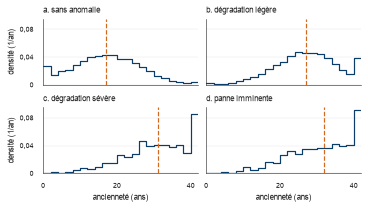

In [15]:
# Grille d'histogrammes par état, ligne médiane et graduations.
fig, axes = plt.subplots(2, 2, figsize=(5.0, 2.8), layout="constrained",
                         sharex=True, sharey=True)
for ax, g, m, t, let in zip(axes.flat, groupes, medianes, titres, "abcd"):
    sns.histplot(g, bins=range(0, 43, 2), stat="density", element="step",
                 fill=False, ax=ax)
    ax.axvline(m, color=ms.ORANGE, linestyle="dashed")
    ax.set_title(f"{let}. {t}", loc="left")
    ax.set(xlabel="ancienneté (ans)", ylabel="densité (1/an)",
           xlim=(0, 42), xticks=[0, 20, 40])
    ms.graduations(ax, 3, "y")
    ax.label_outer()
# Virgule décimale sur tous les axes et enregistrement.
ms.virgule(fig, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c17_facettes.pdf")

#### Chiffrer : statistiques, effectifs, groupes

In [16]:
def resume_numerique(df, groupe=None):
    if groupe is None:
        return df.describe().T
    moyennes = df.groupby(groupe).mean(numeric_only=True)
    return moyennes.assign(
        effectif=df[groupe].value_counts().reindex(moyennes.index))


resume = resume_numerique(df_train)
print(resume[["count", "mean", "50%", "max"]].round(1).head(4))

                                count  mean   50%   max
anciennete_machine_en_annees  16000.0  21.8  22.0  40.0
niveau_complexite_machine     16000.0   1.4   1.3  10.0
nombre_capteurs_installes     16000.0   6.1   6.0  30.0
taux_utilisation_machine      16000.0   0.5   0.5   1.0


#### Lire une dissymétrie

In [17]:
asym = df_train.skew(numeric_only=True).round(1)
print(asym.sort_values().tail(3))            # les plus dissymétriques
etats = df_train["etat_sante_machine"]
print((100 * etats.value_counts(normalize=True)).round(1))

nombre_capteurs_installes     2.9
niveau_complexite_machine     4.4
taux_utilisation_machine     86.1
dtype: float64
etat_sante_machine
RAS                   56.8
Degradation_legere    29.3
Panne_imminente        7.1
Degradation_severe     6.9
Name: proportion, dtype: float64


#### Graphiques des catégories et des paires

[9087, 4685, 1130, 1098]
{'Elevee': 2.03, 'Faible': 2.25, 'Moyenne': 2.06}


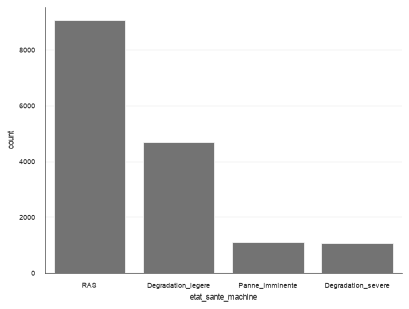

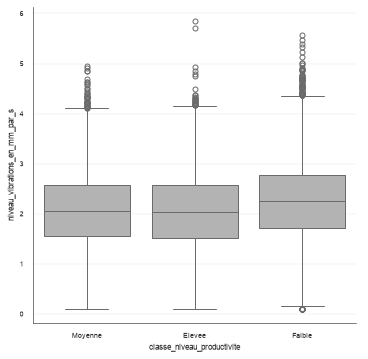

In [18]:
# Compte des effectifs par état de santé
col = "niveau_vibrations_en_mm_par_s"
classe = "classe_niveau_productivite"
ordre = etats.value_counts().index
ax = sns.countplot(x=etats, order=ordre, color="0.45")
print([int(barre.get_height()) for barre in ax.patches])
# Distribution de la variable pour chaque modalité
boites = sns.catplot(
    data=df_train, x=classe, y=col, kind="box", color="0.7"
)
groupes = df_train.groupby(classe)[col]
print(groupes.median().round(2).to_dict())

FacetGrid JointGrid
['Elevee', 'Faible', 'Moyenne']


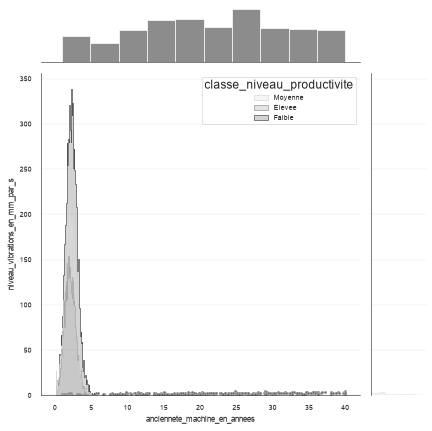

In [19]:
# Nuage conjoint de l'ancienneté et des vibrations
echantillon = df_train.sample(400, random_state=0)
nuage = sns.jointplot(
    data=echantillon, x="anciennete_machine_en_annees", y=col,
    s=8, color="0.4"
)
print(type(boites).__name__, type(nuage).__name__)
# Histogrammes superposés selon la productivité
courbes = sns.histplot(
    data=df_train, x=col, hue=classe, element="step", palette="Greys"
)
textes = [t.get_text() for t in courbes.get_legend().get_texts()]
print(sorted(textes))

#### Des températures par classe

In [20]:
# La température selon la classe de productivité, sur l'apprentissage.
classe = "classe_niveau_productivite"
temperature = "temperature_fonctionnement_en_degC"
ordre = ["Faible", "Moyenne", "Elevee"]
table = df_train[[classe, temperature]].dropna()
medianes = table.groupby(classe)[temperature].median().reindex(ordre)
valeurs = [f"{m:.1f}".replace(".", ",") for m in medianes]
print("médianes (°C) :", " ; ".join(valeurs))
print("températures présentes :", len(table))

médianes (°C) : 83,9 ; 82,7 ; 82,6
températures présentes : 14436


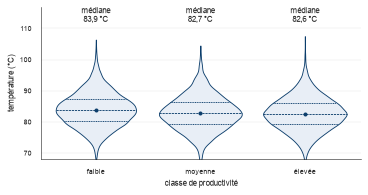

In [21]:
# Un violon par classe, la médiane en point et en valeur.
fig, ax = plt.subplots(figsize=(5.0, 2.6), layout="constrained")
sns.violinplot(data=table, x=classe, y=temperature, order=ordre, color=ms.PALE,
               linecolor=ms.BLEU, inner="quart", cut=0, ax=ax)
ax.plot(range(3), medianes, "o")
# Médiane inscrite au sommet de chaque violon.
for i, m in enumerate(medianes):
    texte = f"médiane\n{m:.1f} °C".replace(".", ",")
    ax.text(i, 117, texte, ha="center", va="top")
ax.set(xlabel="classe de productivité", ylabel="température (°C)")
ax.set_ylim(68, 117)
ax.set_xticks(range(3), ["faible", "moyenne", "élevée"])
ms.virgule(ax)
fig.savefig(DOSSIER_FIGURES / "fig_c17_violons.pdf")

#### Fonction de répartition empirique

In [22]:
# Température selon la productivité et calcul du seuil thermique.
classe = "classe_niveau_productivite"
temp = "temperature_fonctionnement_en_degC"
table = df_train[[classe, temp]].dropna()
seuil = 5 * round(table[temp].median() / 5)
niveaux = ["Faible", "Moyenne", "Elevee"]
labels = ["faible", "moyenne", "élevée"]
props = [0.55, 0.30, 0.10]
# Parts au plus égales au seuil calculées pour chaque niveau.
parts = []
for nom, lab in zip(niveaux, labels):
    p = 100 * (table.loc[table[classe] == nom, temp] <= seuil).mean()
    parts.append(f"{lab} : {p:.1f} %".replace(".", ","))
print(f"seuil : {seuil} °C ; températures présentes : {len(table)}")
print("parts au plus égales au seuil : " + " ; ".join(parts))

seuil : 85 °C ; températures présentes : 14436
parts au plus égales au seuil : faible : 58,5 % ; moyenne : 66,8 % ; élevée : 68,2 %


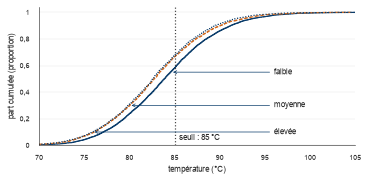

In [23]:
# Tracé des courbes cumulées et annotations des trois classes.
fig, ax = plt.subplots(figsize=(5.0, 2.4), layout="constrained")
traits = ["solid", "dashed", "dotted"]
for nom, lab, trait, q in zip(niveaux, labels, traits, props):
    vals = table.loc[table[classe] == nom, temp]
    sns.ecdfplot(x=vals, linestyle=trait, ax=ax)
    x = vals.quantile(q)
    ax.annotate(lab, (x, q), (96, q), va="center", arrowprops=ms.FLECHE)
# Seuil thermique, repères d'axes et enregistrement de la figure.
ax.axvline(seuil, linestyle="dotted")
ax.text(seuil + 0.5, 0.04, f"seuil : {seuil:g} °C")
ax.set(xlabel="température (°C)", ylabel="part cumulée (proportion)")
ax.set(ylim=(0, 1.04), xlim=(70, 105))
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c17_repartition.pdf")

### Cible et corrélations

#### Corrélations

In [24]:
def correlations(df, cible=None, ax=None):
    corr = df.corr(numeric_only=True)
    if ax is not None:
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="Greys",
                    vmin=-1, vmax=1, ax=ax)
    return corr if cible is None else corr[cible].drop(cible).sort_values()


lien = correlations(df_train, "indice_sante_machine_0_100")
print(lien.round(2).head(3))

niveau_vibrations_en_mm_par_s        -0.91
temperature_fonctionnement_en_degC   -0.87
anciennete_machine_en_annees         -0.61
Name: indice_sante_machine_0_100, dtype: float64


#### Relier ancienneté et vibrations

In [25]:
# Échantillon après nettoyage et coefficient de corrélation linéaire.
age = "anciennete_machine_en_annees"
vibration = "niveau_vibrations_en_mm_par_s"
nuage = df_train[[age, vibration]].dropna().sample(600, random_state=19)
r = nuage[age].corr(nuage[vibration])
print(f"échantillon : {len(nuage)} ; r : {r:.3f}".replace(".", ","))

échantillon : 600 ; r : 0,513


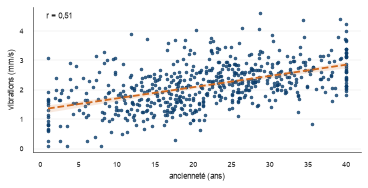

In [26]:
# Nuage de points et régression avec intervalle de confiance.
fig, ax = plt.subplots(figsize=(5.0, 2.5), layout="constrained")
ax.scatter(nuage[age], nuage[vibration], s=8, alpha=0.8)
sns.regplot(data=nuage, x=age, y=vibration, scatter=False, ci=95,
            seed=19, color=ms.ORANGE, ax=ax)
ax.lines[0].set_linestyle("dashed")
texte = f"r = {r:.2f}".replace(".", ",")
ax.annotate(texte, (0.04, 0.92), xycoords="axes fraction")

# Habillage des axes, virgule décimale et enregistrement du graphique.
ax.set(xlabel="ancienneté (ans)", ylabel="vibrations (mm/s)")
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c17_regression.pdf")

#### Relations deux à deux, cible numérique

(150, 25) (120, 25) 9


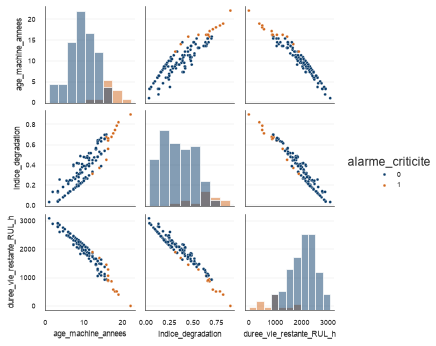

In [27]:
def relations_paires(df, colonnes, hue=None, n_max=400):
    echantillon = df.sample(min(n_max, len(df)), random_state=0)
    garde = list(colonnes) + ([hue] if hue else [])
    return sns.pairplot(echantillon[garde], hue=hue, diag_kind="hist",
                        plot_kws={"s": 8}, height=1.6)


data_sv, sv = lire_classeur("MecaIA-Surveillance_Vibratoire.xlsx")
sv_train, sv_test = decouper(sv)
duo = ["age_machine_annees", "indice_degradation"]
grille = relations_paires(sv_train, duo + ["duree_vie_restante_RUL_h"],
                          hue="alarme_criticite")
print(sv.shape, sv_train.shape, len(grille.axes.flat))

In [28]:
# Détection des corrélations de Pearson et de Spearman
def liens_entre(df_num, seuil=0.85):
    # Coefficients de Pearson et de Spearman
    r = df_num.corr().stack()
    liens = r.to_frame("r")
    liens["rho"] = df_num.corr(method="spearman").stack()
    # Conservation des paires uniques
    liens = liens.reset_index(names=["a", "b"])
    liens = liens[liens["a"] < liens["b"]]
    # Sélection des paires fortes et courbes
    valeurs = liens[["r", "rho"]].abs()
    redondants = valeurs.min(axis=1) >= seuil
    courbes = liens["rho"].abs() - liens["r"].abs() > 0.2
    return liens[redondants], liens[courbes]

In [29]:
# Sélection des colonnes numériques utiles
sans = ["duree_vie_restante_RUL_h", "alarme_criticite"]
brut = sv_train.select_dtypes("number")
df_num = brut.drop(columns=sans)

# Détection des paires et affichage des comptes
redondantes, courbes = liens_entre(df_num)
print(df_num.shape[1], len(redondantes), len(courbes))

# Aperçu des premières corrélations fortes
apercu = redondantes.round(2).head(3)
print(apercu.to_string(index=False))

16 53 0
                 a                       b    r  rho
age_machine_annees vibration_bande_1X_mm_s 0.93 0.92
age_machine_annees      indice_degradation 0.91 0.89
 charge_radiale_kN    vitesse_rotation_rpm 0.97 0.95


#### Comparer trois grandeurs ensemble

In [30]:
# Grandeurs utiles de l'apprentissage et libellés pour le tracé.
colonnes = ["indice_efficacite_energetique",
            "productivite_moyenne_en_pieces_par_heure",
            "temperature_fonctionnement_en_degC"]
libelles = ["efficacité (1)", "productivité\n(pièces/h)", "température (°C)"]

# Tirage de l'échantillon fixé et renommage des variables.
paires = df_train[colonnes].dropna().sample(400, random_state=19)
paires = paires.set_axis(libelles, axis="columns")
print(f"échantillon : {len(paires)} ; variables : {paires.shape[1]}")

échantillon : 400 ; variables : 3


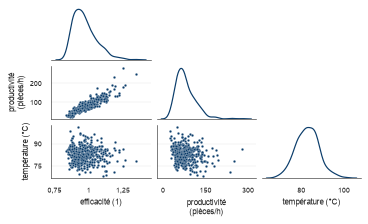

In [31]:
# Grille des paires allégée : points fins, densités sans remplissage.
grille = sns.pairplot(paires, corner=True, diag_kind="kde",
                      plot_kws={"s": 6}, diag_kws={"fill": False})
fig = grille.figure
fig.set_size_inches(5.0, 3.0)
fig.set_layout_engine("constrained")
# Au plus trois graduations par axe, virgule décimale, grille horizontale.
ms.graduations(grille, 3)
ms.virgule(grille, "xy")
for ax in fig.axes:
    ax.grid(True, axis="y")
fig.savefig(DOSSIER_FIGURES / "fig_c17_paires.pdf")

#### Densité de deux grandeurs

In [32]:
# Extraction des mesures et tirage de l'échantillon.
temp = "temperature_fonctionnement_en_degC"
vib = "niveau_vibrations_en_mm_par_s"
table = df_train[[temp, vib]].dropna()
echantillon = table.sample(min(600, len(table)), random_state=23)

# Corrélation linéaire et valeurs imprimées.
r = echantillon[temp].corr(echantillon[vib])
r_val = f"{r:.3f}".replace(".", ",")
print(f"échantillon : {len(echantillon)} ; r : {r_val}")
print(f"paires présentes sur l'apprentissage : {len(table)}")

échantillon : 600 ; r : 0,780
paires présentes sur l'apprentissage : 12953


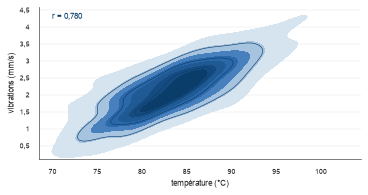

In [33]:
# Densité conjointe : zones remplies, puis trois lignes de niveau.
fig, ax = plt.subplots(figsize=(5.0, 2.6), layout="constrained")
carte = ms.CARTE.resampled(8)
sns.kdeplot(echantillon, x=temp, y=vib, fill=True, levels=8,
            cmap=carte, gridsize=80, cut=0)
sns.kdeplot(echantillon, x=temp, y=vib, levels=[0.2, 0.5, 0.8],
            color=ms.BLEU, linewidths=0.6, gridsize=80, cut=0)
# Titres des axes, corrélation en texte et enregistrement.
ax.set(xlabel="température (°C)", ylabel="vibrations (mm/s)")
ax.annotate(f"r = {r_val}", (0.04, 0.92), xycoords="axes fraction",
            color=ms.BLEU)
ms.virgule(ax, "xy")
fig.savefig(DOSSIER_FIGURES / "fig_c17_densite.pdf")

## Essais des fiches de fonction du chapitre

Chaque fiche du livre donne l'appel minimal d'une fonction. Les cellules suivantes rejouent ces appels, avec les mêmes lignes de code et la même sortie que la fiche : changez une valeur et relisez le résultat.

### Fiche F17-1 : Graphiques statistiques (`seaborn.histplot`)

Moyenne : 19,999 mm
True


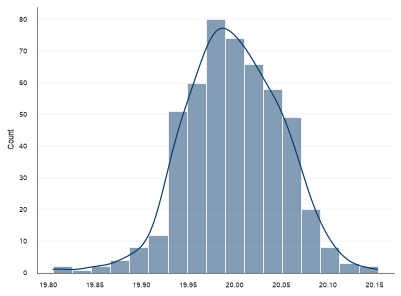

In [34]:
import numpy as np
import seaborn as sns

rng = np.random.default_rng(0)
d = rng.normal(loc=20.0, scale=0.05, size=500)
ax = sns.histplot(x=d, binwidth=0.02, kde=True)
hauteurs = [b.get_height() for b in ax.patches]
moyenne = np.mean(d)                      # diamètre moyen, mm
print(f"Moyenne : {moyenne:.3f} mm".replace(".", ","))
print(np.isclose(sum(hauteurs), len(d)))  # effectif complet